# Phase 1 — Understanding the data: univariate analysis

**Integrated Project — Customer churn analysis and prediction** · ESPRIT School of Business · Business Computing (BI)
**VIGIE · Group BI 5** — Raed Meddeb · Ibrahim Grira · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Supervisors: Aymen Ben Brik and Hela Hammami

---

### What this notebook covers

| Step | Question |
|---|---|
| 1 | Is the loaded file the one that was provided? (integrity, fingerprint) |
| 2 | What is the **grain** of the data, and what are the keys? |
| 3 | How is **churn** defined, and what is its rate at each grain? |
| 4 | Where are the **missing values**, and why? |
| 5 | How is each variable distributed? (**univariate analysis**) |
| 6 | How many **outliers** per numeric variable? (IQR and z-score) |
| 7 | **Summary table** per variable: type, % missing, outliers, decision |

### Confidentiality rule applied here
This notebook shows **no customer row and no identifier**: only counts, distributions and aggregated
indicators. The data stays in `data/` (git-ignored).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve().parents[1]      # .../01_etl/notebooks -> repository root
sys.path.insert(0, str(ROOT))
from vigie import config, data, style

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 100, "display.width", 200)
style.apply()
C = config.COLORS
n = style.thousands

## 1. Loading and integrity

The CSV is read **as is** (everything as text): pandas is not left to guess the types, so that nothing is lost
(leading zeros, `YYYYMMDD` dates, blanks). The SHA-256 fingerprint identifies exactly which file all our figures
were computed on.

In [2]:
raw = data.load_raw()
refs = data.load_references()
fingerprint = data.fingerprint()

expected = {"Rows": 483_536, "Columns": 32, "Distinct customers": 363_024, "Distinct accounts": 410_309}
observed = {
    "Rows": len(raw),
    "Columns": raw.shape[1],
    "Distinct customers": raw["CUSTOMER_NO"].nunique(),
    "Distinct accounts": raw["ACCOUNT_NO"].nunique(),
}
check = pd.DataFrame({"Expected (supervisors' document)": expected, "Observed": observed})
check["Match"] = np.where(check.iloc[:, 0] == check.iloc[:, 1], "✔", "✘")
display(check)
print("SHA-256 of the file:", fingerprint["sha256"])
print("Size               :", n(fingerprint["bytes"]), "bytes")

,Expected (supervisors' document),Observed,Match
Rows,483536,483536,✔
Columns,32,32,✔
Distinct customers,363024,363024,✔
Distinct accounts,410309,410309,✔


SHA-256 of the file: 858551b4293ee1abce4d3aaeac3dea07d817cfd80e111dd52dcff5b06d9fb732
Size               : 75,095,492 bytes


The four volumes stated in the data description document are found to the unit.

### Reference files
Every code in the main file must exist in its reference file (referential integrity).

In [3]:
links = {
    "ACCOUNT_CATEGORY": ("ACCOUNT_CATEGORY", "CATEGORY_ID"),
    "CLOSURE_REASON": ("CLOSURE_REASON", "REASON_ID"),
    "CURRENCY": ("CURRENCY", "CURRENCY_CODE"),
    "INDUSTRY": ("INDUSTRY", "INDUSTRY_CODE"),
    "LOB": ("TARGET", "TARGET_CODE"),
}
rows = []
for column, (file, key) in links.items():
    source_codes = set(raw[column].dropna().unique())
    ref_codes = set(refs[file][key])
    rows.append({
        "Column": column, "Reference file": f"{file}.xlsx", "Key": key,
        "Codes in the reference": len(ref_codes),
        "Codes used": len(source_codes),
        "Orphan codes": len(source_codes - ref_codes),
        "Codes never used": len(ref_codes - source_codes),
    })
display(pd.DataFrame(rows).set_index("Column"))

,Reference file,Key,Codes in the reference,Codes used,Orphan codes,Codes never used
Column,,,,,,
ACCOUNT_CATEGORY,ACCOUNT_CATEGORY.xlsx,CATEGORY_ID,14,14,0,0
CLOSURE_REASON,CLOSURE_REASON.xlsx,REASON_ID,12,12,0,0
CURRENCY,CURRENCY.xlsx,CURRENCY_CODE,5,5,0,0
INDUSTRY,INDUSTRY.xlsx,INDUSTRY_CODE,22,21,0,1
LOB,TARGET.xlsx,TARGET_CODE,6,6,0,0


**Reading.** No orphan code: the five joins are safe. A single reference code is never used (one industry
section), which has no consequence.

## 2. Grain and keys

One row of the file is a **customer / account / product match**. Before computing anything, we need to know
what is being counted.

In [4]:
df = data.cast_types(raw)
with_account = df[df["ACCOUNT_NO"].notna()]

rows_per_account = with_account.groupby("ACCOUNT_NO").size()
rows_per_customer = df.groupby("CUSTOMER_NO").size()
accounts_per_customer = with_account.groupby("CUSTOMER_NO")["ACCOUNT_NO"].nunique()

grain = pd.Series({
    "Rows in the file": len(df),
    "Strictly identical rows (exact duplicates)": int(df.duplicated().sum()),
    "Rows without an account (customers with no account)": int(df["ACCOUNT_NO"].isna().sum()),
    "Share of rows without an account": f"{df['ACCOUNT_NO'].isna().mean():.1%}",
    "Distinct accounts": rows_per_account.size,
    "Accounts present on several rows": int((rows_per_account > 1).sum()),
    "Distinct customers": rows_per_customer.size,
    "Customers with at least one account": accounts_per_customer.size,
    "Customers with no account": rows_per_customer.size - accounts_per_customer.size,
    "Maximum number of rows for one customer (cap)": int(rows_per_customer.max()),
    "Does an account belong to a single customer?": "Yes" if with_account.groupby("ACCOUNT_NO")["CUSTOMER_NO"].nunique().max() == 1 else "No",
}, name="Value")
display(grain.to_frame())

,Value
Rows in the file,483536
Strictly identical rows (exact duplicates),8335
Rows without an account (customers with no account),43984
Share of rows without an account,9.1%
Distinct accounts,410309
Accounts present on several rows,14365
Distinct customers,363024
Customers with at least one account,319040
Customers with no account,43984
Maximum number of rows for one customer (cap),100


In [5]:
# What changes between two rows of the same account?
multi = with_account[with_account["ACCOUNT_NO"].isin(rows_per_account[rows_per_account > 1].index)]
variation = multi.groupby("ACCOUNT_NO").nunique(dropna=True).gt(1).sum()
variation = variation[variation > 0].sort_values(ascending=False)
display(variation.rename("Accounts where the column takes several values").to_frame())

,Accounts where the column takes several values
ACCT_CLOSE_DATE,11807
CLOSURE_REASON,805
FIXEDRATE,16


**Findings on the grain**

* An account always belongs to **a single customer**: `CUSTOMER_NO → ACCOUNT_NO` is a clean 1-to-N relationship.
* When an account appears on several rows, only the **closing date** and, more rarely, the **reason** or the
  **rate** change. The other account attributes are constant.
* About 9% of the rows describe a customer **with no account**: they feed the customer dimension, not the facts.

**Decision — analysis grain.** We work at two grains, depending on the question:

| Grain | Construction | Use |
|---|---|---|
| **Account** | one row per `ACCOUNT_NO`; if several closing dates, the **first** is kept | warehouse (fact table), KPIs, time series |
| **Customer** | one row per `CUSTOMER_NO` | segmentation, churn model |

The first closing date is kept because it marks the churn event; later dates are adjustments of the same account.

In [6]:
accounts = data.account_grain(df)
customers = data.customer_grain(df, accounts)
ref_date = data.reference_date(df)
print(f"Account grain: {n(len(accounts))} rows   |   Customer grain: {n(len(customers))} rows")
print(f"Reference date (last account event observed): {ref_date:%d/%m/%Y}")

Account grain: 410,309 rows   |   Customer grain: 363,024 rows
Reference date (last account event observed): 19/02/2024


## 3. Definition of churn and rate at each grain

As stated in the description document: **churn = 1 if `ACCOUNT_STATUS = "Closed"`**, 0 if `"Active"`,
row excluded if the status is blank.

In [7]:
status_per_customer = accounts.groupby("CUSTOMER_NO")["CHURN"].agg(["min", "max"])
mixed_customers = int((status_per_customer["min"] != status_per_customer["max"]).sum())

rates = pd.DataFrame({
    "Count": [int(with_account["ACCOUNT_STATUS"].notna().sum()), len(accounts),
              int(customers["CHURN"].notna().sum()), len(customers)],
    "Churn": [int((with_account["ACCOUNT_STATUS"] == "Closed").sum()), int(accounts["CHURN"].sum()),
              int(customers["CHURN"].sum()), int(customers["CHURN"].sum())],
}, index=["Row (status filled in)", "Account", "Customer with at least one account", "Customer (all, incl. no account)"])
rates["Churn rate"] = (rates["Churn"] / rates["Count"]).map("{:.1%}".format)
display(rates)
print("Customers holding both an active and a closed account:", mixed_customers)

,Count,Churn,Churn rate
Row (status filled in),439552,177270,40.3%
Account,410309,148215,36.1%
Customer with at least one account,319040,117345,36.8%
"Customer (all, incl. no account)",363024,117345,32.3%


Customers holding both an active and a closed account: 0


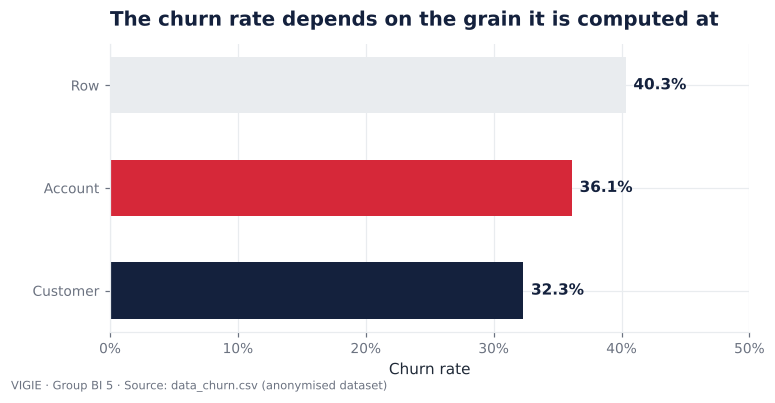

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
values = (rates["Churn"] / rates["Count"]).iloc[[0, 1, 3]]
bars = ax.barh(["Row", "Account", "Customer"], values, color=[C["mist"], C["churn"], C["ink"]], height=0.55)
for b, v in zip(bars, values):
    ax.text(v + 0.006, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", fontweight="bold", color=C["ink"])
ax.set_xlim(0, 0.5)
ax.xaxis.set_major_formatter(style.percent)
ax.invert_yaxis()
ax.set_title("The churn rate depends on the grain it is computed at")
ax.set_xlabel("Churn rate")
style.save(fig, "01_churn_rate_by_grain")
plt.show()

**Reading.** The stated orders of magnitude are found: ≈ 40% of rows, ≈ 36% of accounts, ≈ 32% of customers.
A "per row" rate overstates churn, because closed accounts are repeated more often.

**Key fact: no customer holds both an active and a closed account.** A customer is either entirely active or
entirely gone. The finer definition "customer churn = *all* accounts closed" therefore coincides exactly with
"at least one account closed". This is what lets us model churn **at customer grain** without ambiguity (phase 4).

The imbalance is **moderate** (≈ 36% positives): no rebalancing technique is needed a priori.

## 4. Missing values

Missing values are counted at **row** grain (to compare with the supervisors' document) and then at the
**natural** grain of each variable (customer or account), which is the one that makes business sense.

In [9]:
missing = pd.DataFrame({
    "Natural grain": ["Customer" if c in data.CUSTOMER_COLUMNS else "Account" for c in df.columns],
    "Missing (rows)": df.isna().sum(),
    "% missing (rows)": (df.isna().mean() * 100).round(1),
})
natural_pct = {}
for c in df.columns:
    base = customers if c in data.CUSTOMER_COLUMNS else accounts
    natural_pct[c] = round(base[c].isna().mean() * 100, 1)
missing["% missing (natural grain)"] = pd.Series(natural_pct)
missing = missing.sort_values("% missing (rows)", ascending=False)
display(missing)

,Natural grain,Missing (rows),% missing (rows),% missing (natural grain)
MATURITYDATE,Account,442994,91.6,92.5
FIXEDRATE,Account,432878,89.5,90.1
PRODUCT_STATUS,Account,425498,88.0,89.6
STARTDATE,Account,425494,88.0,89.6
SALARY,Customer,343229,71.0,69.1
CLOSURE_REASON,Account,342070,70.7,67.2
ACCT_CLOSE_DATE,Account,306266,63.3,63.9
COMPLETED_FILE,Customer,235933,48.8,55.0
AMOUNT,Account,210844,43.6,37.7
PRODUCT_GROUP,Account,202223,41.8,36.9


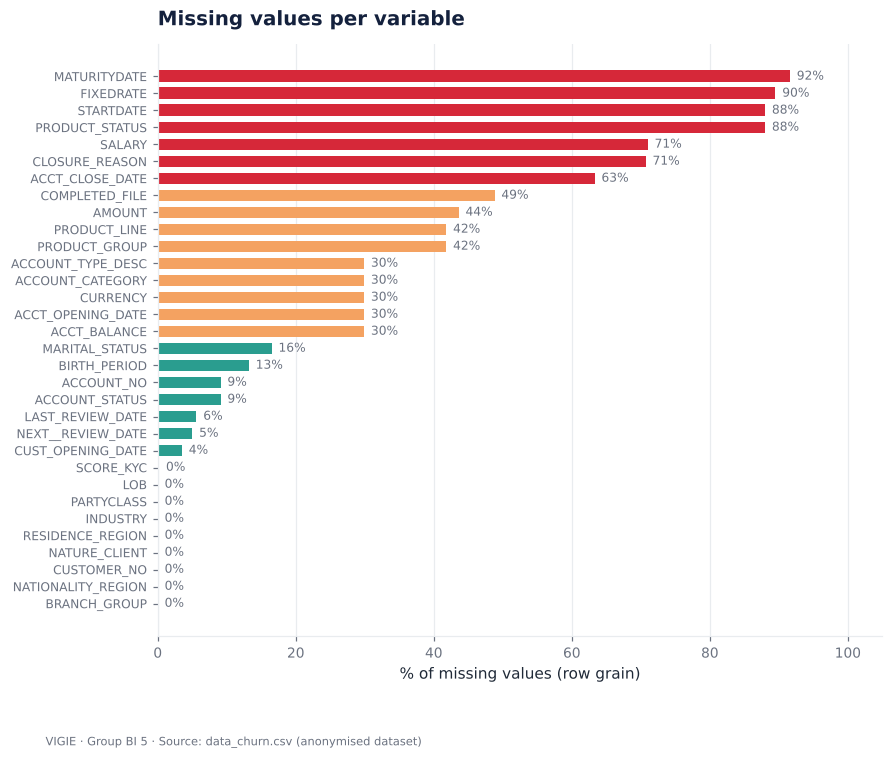

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 7))
m = missing["% missing (rows)"].sort_values()
colors = [C["churn"] if v >= 60 else C["amber"] if v >= 20 else C["retention"] for v in m]
ax.barh(m.index, m, color=colors, height=0.7)
for i, v in enumerate(m):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8, color=C["grey"])
ax.set_xlim(0, 105)
ax.set_xlabel("% of missing values (row grain)")
ax.set_title("Missing values per variable")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
style.save(fig, "01_missing_values")
plt.show()

### Not all blanks are of the same kind

For each account variable, the blank rate is compared between **active** and **closed** accounts.

In [11]:
account_variables = ["ACCT_OPENING_DATE", "ACCOUNT_CATEGORY", "CURRENCY", "ACCT_BALANCE", "ACCT_CLOSE_DATE",
                     "CLOSURE_REASON", "PRODUCT_GROUP", "PRODUCT_LINE", "AMOUNT", "STARTDATE", "MATURITYDATE",
                     "FIXEDRATE", "PRODUCT_STATUS"]
blank_by_status = (accounts.groupby("ACCOUNT_STATUS")[account_variables]
                   .agg(lambda s: round(s.isna().mean() * 100, 1)).T)
blank_by_status.columns = [f"% blank — {c}" for c in blank_by_status.columns]
blank_by_status["Gap (points)"] = (blank_by_status.iloc[:, 1] - blank_by_status.iloc[:, 0]).round(1)
display(blank_by_status.sort_values("Gap (points)", ascending=False))

,% blank — Active,% blank — Closed,Gap (points)
ACCT_OPENING_DATE,0.0,67.8,67.8
ACCOUNT_CATEGORY,0.0,67.8,67.8
CURRENCY,0.0,67.8,67.8
ACCT_BALANCE,0.0,67.8,67.8
AMOUNT,15.0,77.7,62.7
PRODUCT_LINE,14.7,76.0,61.3
PRODUCT_GROUP,14.7,76.0,61.3
FIXEDRATE,89.1,91.9,2.8
MATURITYDATE,92.0,93.4,1.4
PRODUCT_STATUS,89.1,90.4,1.3


**Typology of blanks** (used in the final summary table):

| Kind of blank | Variables | Explanation |
|---|---|---|
| **Structural** | every account and product column on rows without `ACCOUNT_NO` | the customer has no account: there is nothing to fill in |
| **Business** | `ACCT_CLOSE_DATE`, `CLOSURE_REASON` | an active account has neither a closing date nor a reason |
| **Business** | `STARTDATE`, `MATURITYDATE`, `FIXEDRATE`, `PRODUCT_STATUS` | only apply to products with a maturity (loans, term deposits) |
| **Tied to the closure** ⚠ | `ACCT_OPENING_DATE`, `ACCOUNT_CATEGORY`, `CURRENCY`, `ACCT_BALANCE`, `PRODUCT_GROUP`, `AMOUNT` | blank for ≈ 68% of closed accounts, **never** for active ones |
| **Declarative / anonymisation** | `SALARY`, `MARITAL_STATUS`, `BIRTH_PERIOD`, `COMPLETED_FILE` | not declared, or masked to guarantee k-anonymity |

⚠ **Major point of attention for phase 4.** The blanks "tied to the closure" are not an ordinary quality
defect: they **give the target away**. Knowing that the balance is blank is almost enough to know that the
account is closed. These columns — and any indicator derived from their blankness — are therefore excluded from
the explanatory variables (detailed check in `04_machine_learning/notebooks/03_churn_ml.ipynb`).

## 5. Univariate analysis

### 5.1 Qualitative customer variables (customer grain)

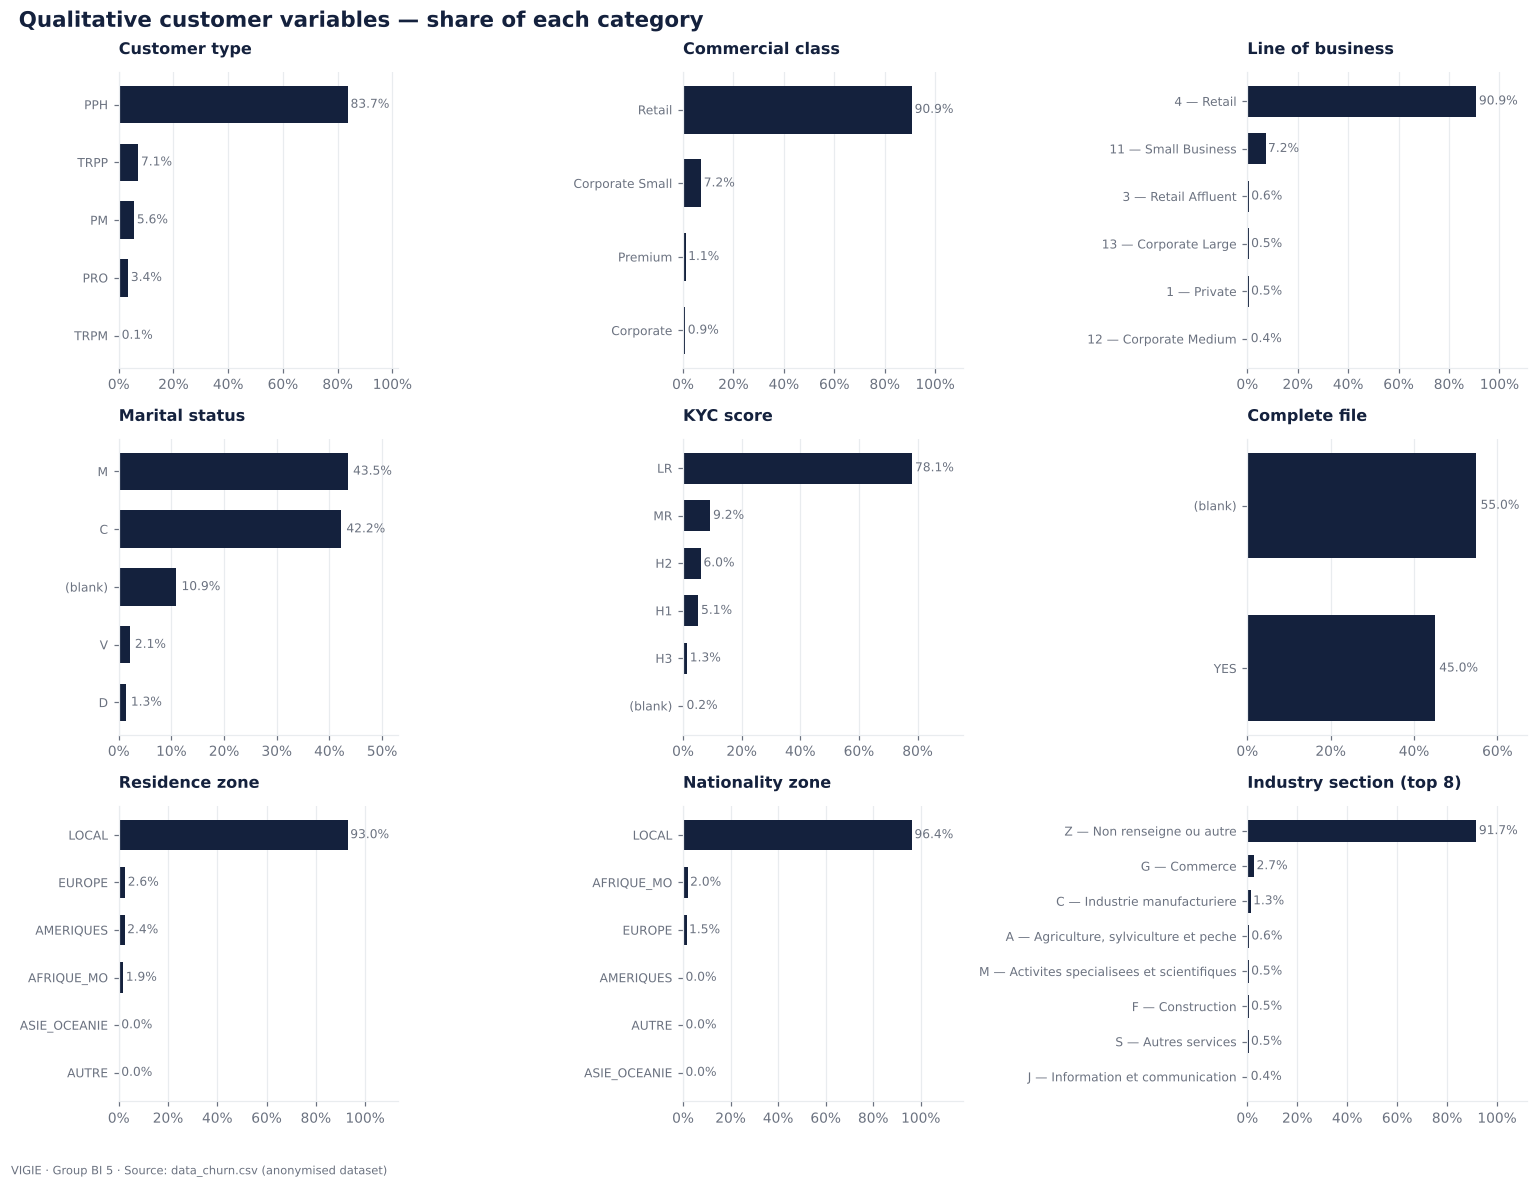

In [12]:
def category_table(series: pd.Series, labels: dict | None = None, top: int = 8) -> pd.DataFrame:
    """Count and share of each category (blanks form a category)."""
    s = series.astype("object").where(series.notna(), "(blank)")
    t = s.value_counts().to_frame("Count")
    t["Share"] = (t["Count"] / t["Count"].sum()).map("{:.1%}".format)
    if labels:
        t.insert(0, "Label", [labels.get(i, "") for i in t.index])
    return t.head(top)


def category_bars(ax, series, title, color, top=8, labels=None):
    s = series.astype("object").where(series.notna(), "(blank)")
    shares = (s.value_counts(normalize=True)).head(top)[::-1]
    names = [f"{i} — {labels[i]}" if labels and i in labels else str(i) for i in shares.index]
    ax.barh(names, shares, color=color, height=0.65)
    for i, v in enumerate(shares):
        ax.text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=8, color=C["grey"])
    ax.set_xlim(0, max(shares.max() * 1.22, 0.1))
    ax.xaxis.set_major_formatter(style.percent)
    ax.set_title(title, fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)


industry_labels = dict(zip(refs["INDUSTRY"]["INDUSTRY_CODE"], refs["INDUSTRY"]["DESCRIPTION"]))
lob_labels = dict(zip(refs["TARGET"]["TARGET_CODE"], refs["TARGET"]["DESCRIPTION"]))

fig, axes = plt.subplots(3, 3, figsize=(14, 10.5))
plan = [
    ("NATURE_CLIENT", "Customer type", None), ("PARTYCLASS", "Commercial class", None),
    ("LOB", "Line of business", lob_labels), ("MARITAL_STATUS", "Marital status", None),
    ("SCORE_KYC", "KYC score", None), ("COMPLETED_FILE", "Complete file", None),
    ("RESIDENCE_REGION", "Residence zone", None), ("NATIONALITY_REGION", "Nationality zone", None),
    ("INDUSTRY", "Industry section (top 8)", industry_labels),
]
for ax, (col, title, lab) in zip(axes.ravel(), plan):
    category_bars(ax, customers[col], title, C["ink"], labels=lab)
fig.suptitle("Qualitative customer variables — share of each category", x=0.01, ha="left",
             fontweight="bold", color=C["ink"], fontsize=14)
fig.tight_layout()
style.save(fig, "01_univariate_customer_qualitative")
plt.show()

In [13]:
for col, title, lab in plan:
    display(Markdown(f"**{title}** (`{col}`) — {customers[col].nunique()} categories"))
    display(category_table(customers[col], lab))

**Customer type** (`NATURE_CLIENT`) — 5 categories

,Count,Share
NATURE_CLIENT,,
PPH,303908,83.7%
TRPP,25888,7.1%
PM,20474,5.6%
PRO,12460,3.4%
TRPM,294,0.1%


**Commercial class** (`PARTYCLASS`) — 4 categories

,Count,Share
PARTYCLASS,,
Retail,329842,90.9%
Corporate Small,26211,7.2%
Premium,3812,1.1%
Corporate,3159,0.9%


**Line of business** (`LOB`) — 6 categories

,Label,Count,Share
LOB,,,
4,Retail,329842,90.9%
11,Small Business,26211,7.2%
3,Retail Affluent,2008,0.6%
13,Corporate Large,1865,0.5%
1,Private,1804,0.5%
12,Corporate Medium,1294,0.4%


... (8 outputs left out)

**Nationality zone** (`NATIONALITY_REGION`) — 6 categories

,Count,Share
NATIONALITY_REGION,,
LOCAL,349793,96.4%
AFRIQUE_MO,7238,2.0%
EUROPE,5581,1.5%
AMERIQUES,169,0.0%
AUTRE,136,0.0%
ASIE_OCEANIE,107,0.0%


**Industry section (top 8)** (`INDUSTRY`) — 21 categories

,Label,Count,Share
INDUSTRY,,,
Z,Non renseigne ou autre,332986,91.7%
G,Commerce,9798,2.7%
C,Industrie manufacturiere,4830,1.3%
A,"Agriculture, sylviculture et peche",2253,0.6%
M,Activites specialisees et scientifiques,1986,0.5%
F,Construction,1878,0.5%
S,Autres services,1739,0.5%
J,Information et communication,1297,0.4%


**Reading — qualitative customer variables**

* The customer base is overwhelmingly made of **individuals**: 84% natural persons (`PPH`) and 91% of customers
  in the **Retail** segment. Legal entities (`PM`) and professionals (`PRO`) are a minority to follow separately.
* The `TRPP` and `TRPM` categories (7% of customers) almost **never hold an account**: they drop out of the
  churn scope by themselves.
* `PARTYCLASS` and `LOB` carry almost the same information (the commercial segment): one of the two is enough
  for modelling.
* `INDUSTRY` equals `Z` ("not provided or other") for more than 9 customers out of 10: the variable is mostly
  informative for legal entities and professionals.
* `COMPLETED_FILE` only takes the value `YES`: a blank means "incomplete file". It is recoded as 0/1.
* Residence and nationality zones: 93% and 96% `LOCAL`. The other categories are rare.

### 5.2 Branch groups

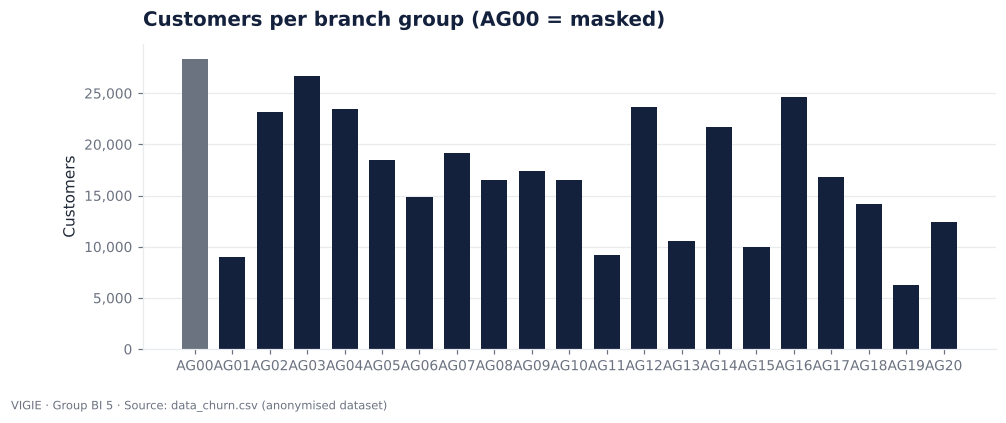

Smallest group: 6,228 customers · largest: 28,378 · AG00 (masked): 7.8% of customers


In [14]:
fig, ax = plt.subplots(figsize=(10, 3.6))
bg = customers["BRANCH_GROUP"].value_counts().sort_index()
ax.bar(bg.index, bg.values, color=[C["grey"] if i == "AG00" else C["ink"] for i in bg.index], width=0.7)
ax.yaxis.set_major_formatter(style.thousands)
ax.set_title("Customers per branch group (AG00 = masked)")
ax.set_ylabel("Customers")
ax.grid(axis="x", visible=False)
style.save(fig, "01_univariate_branch_groups")
plt.show()
print(f"Smallest group: {n(bg.min())} customers · largest: {n(bg.max())} · AG00 (masked): {bg['AG00'] / bg.sum():.1%} of customers")

The 21 groupings all have a meaningful size (from 6,000 to 28,000 customers): they can serve as an analysis axis.
`AG00` gathers the branches masked by the anonymisation and cannot be interpreted.

### 5.3 Quantitative customer variables

In [15]:
customers["AGE"] = ref_date.year - (customers["BIRTH_PERIOD"] + 2)
customers["CUSTOMER_TENURE"] = (ref_date - customers["CUST_OPENING_DATE"]).dt.days / 365.25
customers["MONTHS_SINCE_REVIEW"] = (ref_date - customers["LAST_REVIEW_DATE"]).dt.days / 30.4375
customers["MONTHS_TO_NEXT_REVIEW"] = (customers["NEXT__REVIEW_DATE"] - ref_date).dt.days / 30.4375

customer_quant = {
    "AGE": "Age (years, middle of the band)",
    "CUSTOMER_TENURE": "Customer tenure (years)",
    "N_ACCOUNTS": "Number of accounts",
    "SALARY": "Declared income",
    "MONTHS_SINCE_REVIEW": "Months since last review",
    "MONTHS_TO_NEXT_REVIEW": "Months to next review",
}


def summary(series: pd.Series) -> pd.Series:
    s = series.dropna().astype(float)
    return pd.Series({
        "n": len(s), "Mean": s.mean(), "Std dev": s.std(), "Min": s.min(), "Q1": s.quantile(.25),
        "Median": s.median(), "Q3": s.quantile(.75), "Max": s.max(),
        "Skewness": s.skew(), "Mode": s.mode().iloc[0],
    })


customer_stats = pd.DataFrame({lab: summary(customers.loc[customers["N_ACCOUNTS"] > 0, col] if col == "N_ACCOUNTS" else customers[col])
                               for col, lab in customer_quant.items()}).T
display(customer_stats.round(2))

,n,Mean,Std dev,Min,Q1,Median,Q3,Max,Skewness,Mode
"Age (years, middle of the band)",339679.0,48.09,16.74,2.00,37.00,47.00,62.00,87.00,0.17,42.00
Customer tenure (years),347422.0,11.71,6.59,0.13,6.13,10.38,18.13,24.13,0.20,21.39
Number of accounts,319040.0,1.29,1.16,1.00,1.00,1.00,1.00,92.00,17.53,1.00
Declared income,112277.0,794.09,657.31,1.00,400.00,400.00,1000.00,5000.00,2.19,400.00
Months since last review,336120.0,52.41,42.54,0.59,20.63,44.62,69.65,256.62,1.61,69.65
Months to next review,338950.0,-8.27,43.33,-232.61,-21.65,-3.61,21.39,58.41,-1.67,-21.65


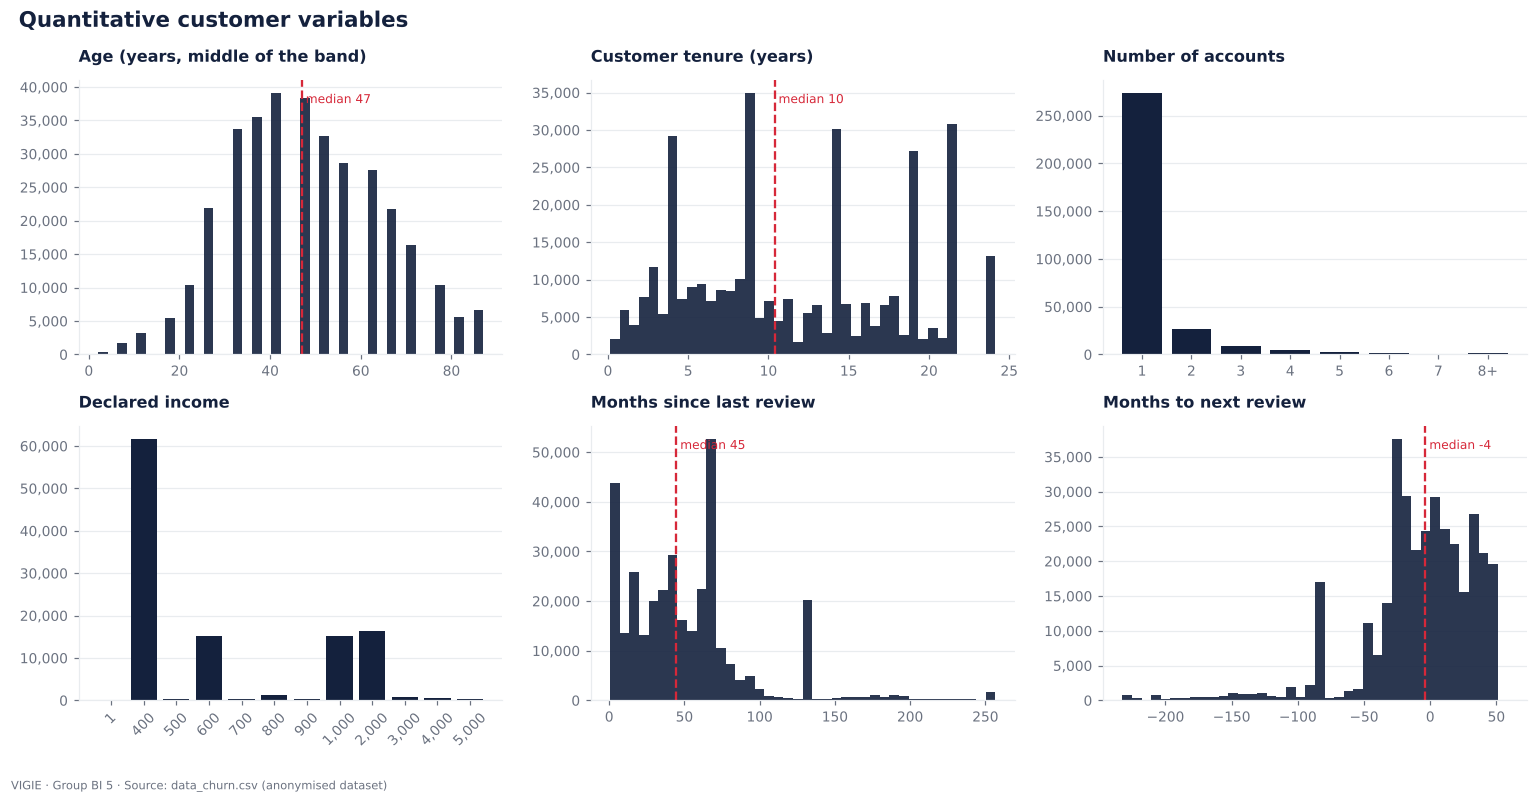

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, lab) in zip(axes.ravel(), customer_quant.items()):
    s = customers[col].dropna()
    if col == "N_ACCOUNTS":
        s = s[s > 0].clip(upper=8)
        v = s.value_counts().sort_index()
        ax.bar([str(int(i)) if i < 8 else "8+" for i in v.index], v.values, color=C["ink"])
    elif col == "SALARY":
        v = s.value_counts().sort_index()
        ax.bar([n(i) for i in v.index], v.values, color=C["ink"])
        ax.tick_params(axis="x", rotation=45)
    else:
        ax.hist(s, bins=40, color=C["ink"], alpha=0.9)
        ax.axvline(s.median(), color=C["churn"], lw=1.5, ls="--")
        ax.text(s.median(), ax.get_ylim()[1] * 0.95, f" median {s.median():.0f}", color=C["churn"], fontsize=8, va="top")
    ax.yaxis.set_major_formatter(style.thousands)
    ax.set_title(lab, fontsize=10.5)
    ax.grid(axis="x", visible=False)
fig.suptitle("Quantitative customer variables", x=0.01, ha="left", fontweight="bold", color=C["ink"], fontsize=14)
fig.tight_layout()
style.save(fig, "01_univariate_customer_quantitative")
plt.show()

**Reading — quantitative customer variables**

* **Age**: a spread-out distribution centred around 47. Age is rebuilt at the middle of the 5-year birth band:
  it is an order of magnitude, not an exact value. Minors exist (savings accounts opened by parents).
* **Tenure**: visible "steps", because `CUST_OPENING_DATE` is generalised (quarter, year or 5-year period
  depending on the customer). To be read in bands.
* **Number of accounts**: highly concentrated — the vast majority of customers hold **a single account**.
* **Declared income**: rounded to one significant figure, hence only a dozen values, and blank for ≈ 7 customers
  out of 10. In practice it is an ordinal variable. The value `1` is a technical entry.
* **File reviews**: the last review is, at the median, nearly 4 years old; a negative value of "months to next
  review" means the review is **overdue**.

### 5.4 Account variables (account grain)

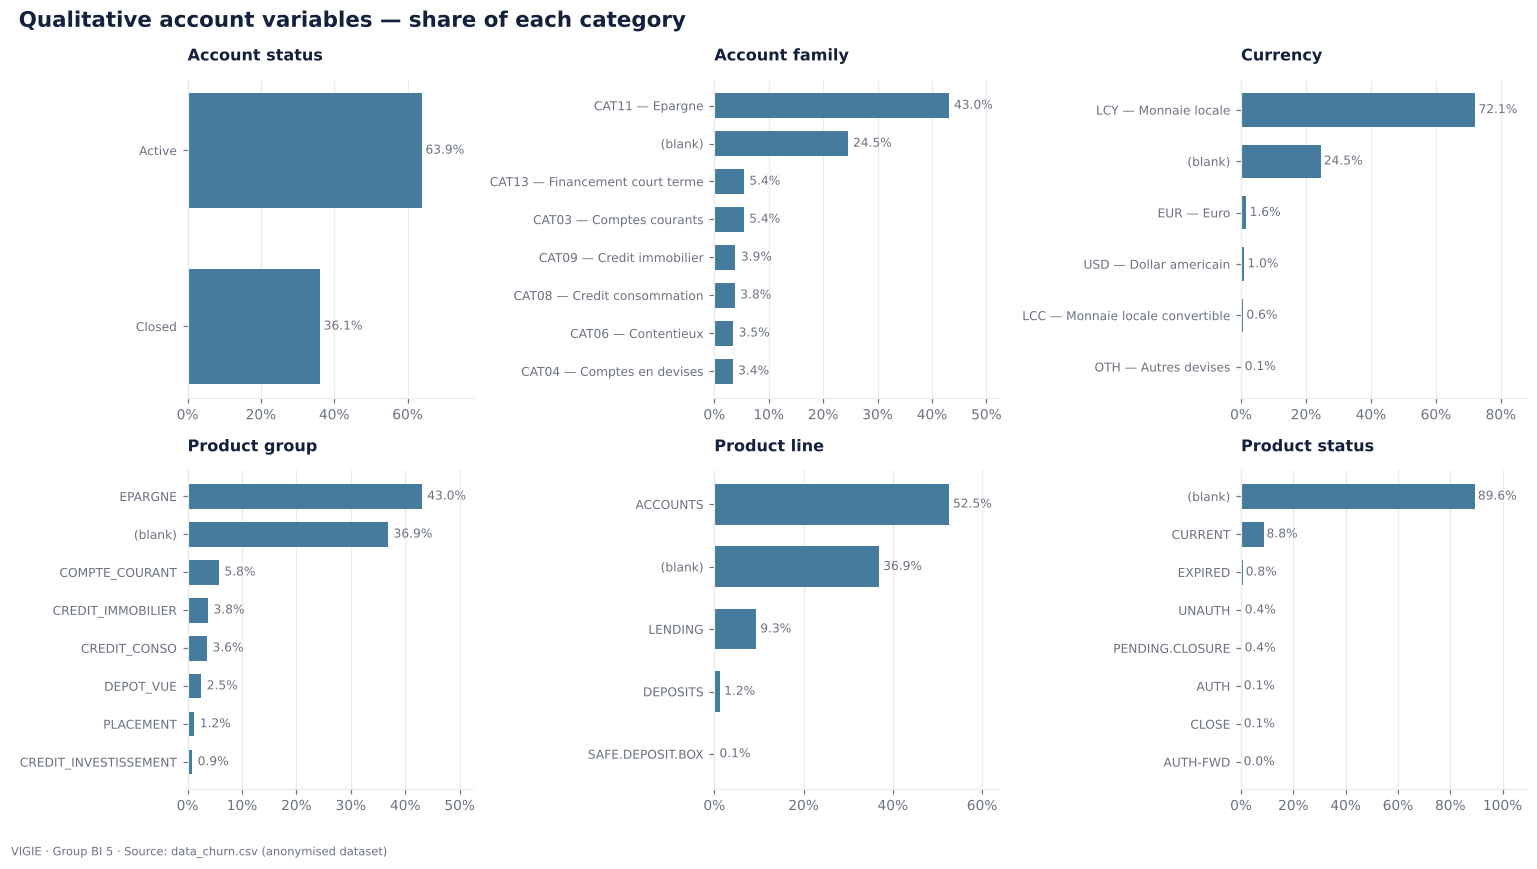

In [17]:
category_labels = dict(zip(refs["ACCOUNT_CATEGORY"]["CATEGORY_ID"], refs["ACCOUNT_CATEGORY"]["DESCRIPTION"]))
currency_labels = dict(zip(refs["CURRENCY"]["CURRENCY_CODE"], refs["CURRENCY"]["DESCRIPTION"]))
reason_labels = dict(zip(refs["CLOSURE_REASON"]["REASON_ID"], refs["CLOSURE_REASON"]["DESCRIPTION"]))

fig, axes = plt.subplots(2, 3, figsize=(14, 7.6))
account_plan = [
    ("ACCOUNT_STATUS", "Account status", None), ("ACCOUNT_CATEGORY", "Account family", category_labels),
    ("CURRENCY", "Currency", currency_labels), ("PRODUCT_GROUP", "Product group", None),
    ("PRODUCT_LINE", "Product line", None), ("PRODUCT_STATUS", "Product status", None),
]
for ax, (col, title, lab) in zip(axes.ravel(), account_plan):
    category_bars(ax, accounts[col], title, C["sky"], labels=lab)
fig.suptitle("Qualitative account variables — share of each category", x=0.01, ha="left",
             fontweight="bold", color=C["ink"], fontsize=14)
fig.tight_layout()
style.save(fig, "01_univariate_account_qualitative")
plt.show()

In [18]:
closed = accounts[accounts["CHURN"] == 1]
reasons = category_table(closed["CLOSURE_REASON"], reason_labels, top=13)
display(Markdown("**Closure reasons** (closed accounts only)"))
display(reasons)

**Closure reasons** (closed accounts only)

,Label,Count,Share
CLOSURE_REASON,,,
RSN01,Autre,120129,81.1%
(blank),,13509,9.1%
RSN02,Cessation d'activite,10547,7.1%
RSN03,Changement d'adresse,1803,1.2%
RSN05,Deces,902,0.6%
RSN12,Transfert interne,418,0.3%
RSN10,Refus de credit,269,0.2%
RSN11,Tarification,248,0.2%
RSN04,Changement d'employeur,220,0.1%


**Reading — account variables**

* **Savings** (*Epargne*) dominate the portfolio by far; short-term financing and current accounts follow.
  The currency is the **local currency** in the overwhelming majority of cases.
* The closure reason is `RSN01 — Autre` (Other) in the great majority of cases: it is **not very informative**.
  The "competitive" reasons (competing offer, pricing, quality of service) are marginal. Churn therefore cannot
  be explained by the declared reason; one has to go through the customer's profile.

The labels of account families, currencies and reasons are shown as they appear in the reference files.

### 5.5 Quantitative account variables

In [19]:
account_quant = {"ACCT_BALANCE": "Account balance", "AMOUNT": "Product amount", "FIXEDRATE": "Fixed rate (%)"}
account_stats = pd.DataFrame({lab: summary(accounts[col]) for col, lab in account_quant.items()}).T
display(account_stats.round(2))

balance = accounts["ACCT_BALANCE"].dropna()
amount = accounts["AMOUNT"].dropna()
print(f"Negative balances (accounts in debit): {n((balance < 0).sum())}, i.e. {(balance < 0).mean():.1%} of filled-in balances")
print(f"Zero balances                        : {n((balance == 0).sum())}, i.e. {(balance == 0).mean():.1%}")
print(f"Balances at the upper cap ({n(balance.max())}) : {n((balance == balance.max()).sum())} accounts")
print(f"Balances at the lower cap ({n(balance.min())}): {n((balance == balance.min()).sum())} accounts")
print(f"Amounts at the cap ({n(amount.max())})     : {n((amount == amount.max()).sum())} accounts")

,n,Mean,Std dev,Min,Q1,Median,Q3,Max,Skewness,Mode
Account balance,309831.0,-2054.71,3.040538e+05,-11000000.0,0.0,6.0,1600.0,1.100000e+07,-4.60,0.0
Product amount,255796.0,12868754.50,1.953694e+08,-44000000.0,4.6,560.0,19000.0,9.000000e+09,34.01,0.0
Fixed rate (%),40442.0,9.10,2.480000e+00,0.0,8.5,10.0,11.0,1.350000e+01,-1.14,11.0


Negative balances (accounts in debit): 60,387, i.e. 19.5% of filled-in balances
Zero balances                        : 62,994, i.e. 20.3%
Balances at the upper cap (11,000,000) : 40 accounts
Balances at the lower cap (-11,000,000): 42 accounts
Amounts at the cap (9,000,000,000)     : 52 accounts


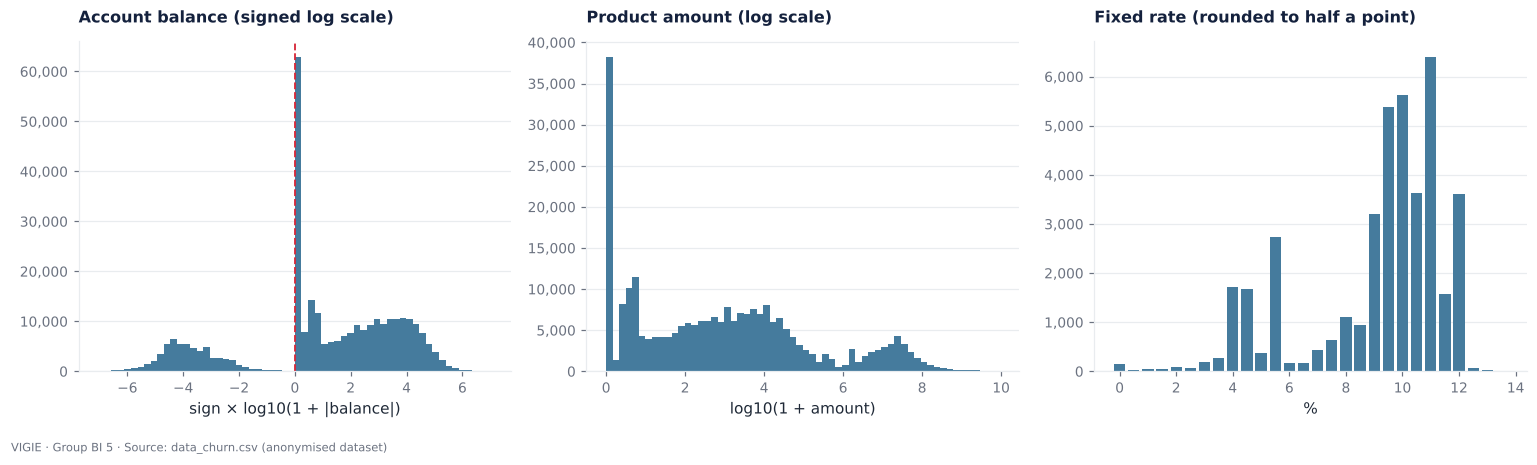

In [20]:
def signed_log(x):
    """Logarithmic scale that keeps the sign: useful for negative, widely spread balances."""
    return np.sign(x) * np.log10(1 + np.abs(x))


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(signed_log(balance), bins=60, color=C["sky"])
axes[0].axvline(0, color=C["churn"], lw=1.2, ls="--")
axes[0].set_title("Account balance (signed log scale)", fontsize=10.5)
axes[0].set_xlabel("sign × log10(1 + |balance|)")
axes[1].hist(np.log10(1 + amount.clip(lower=0)), bins=60, color=C["sky"])
axes[1].set_title("Product amount (log scale)", fontsize=10.5)
axes[1].set_xlabel("log10(1 + amount)")
fixed_rate = accounts["FIXEDRATE"].dropna().value_counts().sort_index()
axes[2].bar(fixed_rate.index, fixed_rate.values, width=0.4, color=C["sky"])
axes[2].set_title("Fixed rate (rounded to half a point)", fontsize=10.5)
axes[2].set_xlabel("%")
for ax in axes:
    ax.yaxis.set_major_formatter(style.thousands)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
style.save(fig, "01_univariate_account_quantitative")
plt.show()

**Reading — quantitative account variables**

* **Balance**: an extremely spread-out, skewed distribution, with a mass at zero and a notable share of
  **negative balances** (≈ 1 balance in 5). These are not errors: they are accounts **in debit** (overdrafts,
  outstanding loans). Extreme values are **capped** by the anonymisation (± 11,000,000): a few dozen accounts
  sit exactly on the bound, which is not a business phenomenon.
* **Amount**: same shape, even more spread out, with the same artificial pile-up on the cap value.
* **Fixed rate**: discrete values (half points), filled in only for loans and term deposits. Loans (median of
  9 to 11% depending on the type) sit a little above term deposits (median 8%).

As a consequence, these amounts are read as **orders of magnitude** (median, bands), never as absolute totals.

### 5.6 Date variables

In [21]:
dates = {
    "CUST_OPENING_DATE": ("Start of relationship", customers), "LAST_REVIEW_DATE": ("Last review", customers),
    "NEXT__REVIEW_DATE": ("Next review", customers), "ACCT_OPENING_DATE": ("Account opening", accounts),
    "ACCT_CLOSE_DATE": ("Account closing", accounts), "STARTDATE": ("Product start", accounts),
    "MATURITYDATE": ("Product maturity", accounts),
}
date_summary = pd.DataFrame({
    lab: {
        "Filled in": int(base[col].notna().sum()), "Minimum": f"{base[col].min():%d/%m/%Y}",
        "Median": f"{base[col].dropna().median():%d/%m/%Y}", "Maximum": f"{base[col].max():%d/%m/%Y}",
        "Distinct values": base[col].nunique(),
        "Always a Monday": "Yes" if (base[col].dropna().dt.day_of_week == 0).all() else "No",
        "Always the 1st of the month": "Yes" if (base[col].dropna().dt.day == 1).all() else "No",
    } for col, (lab, base) in dates.items()
}).T
display(date_summary)
invalid = {c: int((raw[c].notna() & df[c].isna()).sum()) for c in data.DATE_COLUMNS}
print("Dates that could not be converted (invalid format):", invalid)

,Filled in,Minimum,Median,Maximum,Distinct values,Always a Monday,Always the 1st of the month
Start of relationship,347422,01/01/2000,01/10/2013,01/01/2024,87,No,Yes
Last review,336120,01/10/2002,01/06/2020,01/02/2024,257,No,Yes
Next review,338950,01/10/2004,01/11/2023,01/01/2029,283,No,Yes
Account opening,309831,02/01/1978,08/10/2018,19/02/2024,2188,Yes,No
Account closing,148215,13/04/2020,01/11/2021,19/02/2024,191,Yes,No
Product start,42859,01/12/2011,01/12/2023,01/12/2024,75,No,Yes
Product maturity,30871,01/08/2007,01/02/2025,01/01/2031,221,No,Yes


Dates that could not be converted (invalid format): {'CUST_OPENING_DATE': 0, 'LAST_REVIEW_DATE': 0, 'NEXT__REVIEW_DATE': 0, 'ACCT_OPENING_DATE': 0, 'ACCT_CLOSE_DATE': 0, 'STARTDATE': 0, 'MATURITYDATE': 0}


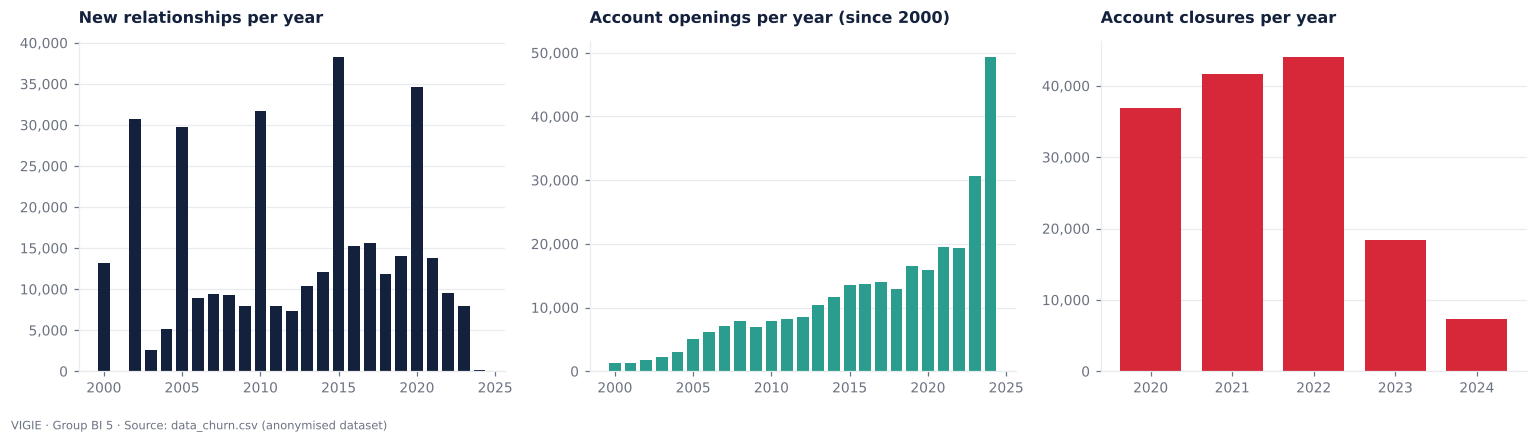

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, title, base, color) in zip(axes, [
        ("CUST_OPENING_DATE", "New relationships per year", customers, C["ink"]),
        ("ACCT_OPENING_DATE", "Account openings per year (since 2000)", accounts, C["retention"]),
        ("ACCT_CLOSE_DATE", "Account closures per year", accounts, C["churn"])]):
    per_year = base[col].dropna().dt.year.value_counts().sort_index()
    per_year = per_year[per_year.index >= 2000]
    ax.bar(per_year.index, per_year.values, color=color, width=0.75)
    ax.yaxis.set_major_formatter(style.thousands)
    ax.set_title(title, fontsize=10.5)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
style.save(fig, "01_univariate_dates")
plt.show()

In [23]:
# Consistency between dates: an account cannot be closed before it was opened.
both_dates = accounts[accounts["ACCT_OPENING_DATE"].notna() & accounts["ACCT_CLOSE_DATE"].notna()]
inconsistent = int((both_dates["ACCT_CLOSE_DATE"] < both_dates["ACCT_OPENING_DATE"]).sum())
print(f"Closed accounts whose opening date is filled in : {n(len(both_dates))}")
print(f"… of which closing BEFORE opening               : {n(inconsistent)} ({inconsistent / len(both_dates):.1%})")
gap = (both_dates["ACCT_OPENING_DATE"] - both_dates["ACCT_CLOSE_DATE"]).dt.days
print(f"Median gap for these accounts                   : {gap[gap > 0].median():.0f} days")

Closed accounts whose opening date is filled in : 47,737
… of which closing BEFORE opening               : 20,166 (42.2%)
Median gap for these accounts                   : 434 days


**Reading — dates**

* Every date is **convertible** (no invalid format): the `YYYYMMDD → date` conversion is safe.
* They have **different precisions**, to be respected: account dates are brought back to the **Monday** (weekly
  grain), review and product dates to the **1st of the month** (monthly grain), and the start of relationship
  to the start of a quarter, a year or a 5-year period.
* Closures only span **about 47 months**: this is the churn observation window, and the reason why the phase 4
  time series is built at **weekly** grain.
* Since the dates were shifted, we reason in **durations** (tenure, delays), never in calendar dates.
* **Anomaly to report**: among closed accounts whose opening date is known, more than four in ten have a closing
  date *earlier* than the opening date. Added to the fact that this date is blank for 68% of closed accounts,
  this makes **account age unusable** for closed accounts. Decision: in the warehouse these accounts are flagged
  and their age is not computed; in modelling we use the **customer's** tenure, which does not suffer from this.

## 6. Outliers

Two methods are applied to every numeric variable:

* **IQR**: value outside `[Q1 − 1.5 × IQR ; Q3 + 1.5 × IQR]` — robust, assumes no normal distribution;
* **z-score**: `|x − mean| / standard deviation > 3` — classic, but sensitive to the extreme values themselves.

**IQR is our reference method**, because none of these variables follows a normal distribution.

In [24]:
def outliers(series: pd.Series) -> dict:
    s = series.dropna().astype(float)
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return {
        "n": len(s), "IQR lower bound": low, "IQR upper bound": high,
        "Low outliers (IQR)": int((s < low).sum()), "High outliers (IQR)": int((s > high).sum()),
        "IQR outliers": int(((s < low) | (s > high)).sum()),
        "% IQR": round(((s < low) | (s > high)).mean() * 100, 1),
        "z-score outliers": int((z.abs() > 3).sum()),
        "% z-score": round((z.abs() > 3).mean() * 100, 1),
    }


numeric = {
    "ACCT_BALANCE": accounts["ACCT_BALANCE"], "AMOUNT": accounts["AMOUNT"], "FIXEDRATE": accounts["FIXEDRATE"],
    "SALARY": customers["SALARY"], "BIRTH_PERIOD": customers["BIRTH_PERIOD"],
    "N_ACCOUNTS (derived)": customers.loc[customers["N_ACCOUNTS"] > 0, "N_ACCOUNTS"],
    "CUSTOMER_TENURE (derived)": customers["CUSTOMER_TENURE"],
    "MONTHS_SINCE_REVIEW (derived)": customers["MONTHS_SINCE_REVIEW"],
}
outlier_table = pd.DataFrame({name: outliers(s) for name, s in numeric.items()}).T
display(outlier_table.round(1))

,n,IQR lower bound,IQR upper bound,Low outliers (IQR),High outliers (IQR),IQR outliers,% IQR,z-score outliers,% z-score
ACCT_BALANCE,309831.0,-2400.0,4000.0,39899.0,59463.0,99362.0,32.1,1685.0,0.5
AMOUNT,255796.0,-28488.5,47493.1,1123.0,50113.0,51236.0,20.0,852.0,0.3
FIXEDRATE,40442.0,4.8,14.8,4299.0,0.0,4299.0,10.6,258.0,0.6
SALARY,112277.0,-500.0,1900.0,0.0,17899.0,17899.0,15.9,1620.0,1.4
BIRTH_PERIOD,339679.0,1922.5,2022.5,0.0,0.0,0.0,0.0,0.0,0.0
N_ACCOUNTS (derived),319040.0,1.0,1.0,0.0,45465.0,45465.0,14.3,5325.0,1.7
CUSTOMER_TENURE (derived),347422.0,-11.9,36.1,0.0,0.0,0.0,0.0,0.0,0.0
MONTHS_SINCE_REVIEW (derived),336120.0,-52.9,143.2,0.0,10468.0,10468.0,3.1,6693.0,2.0


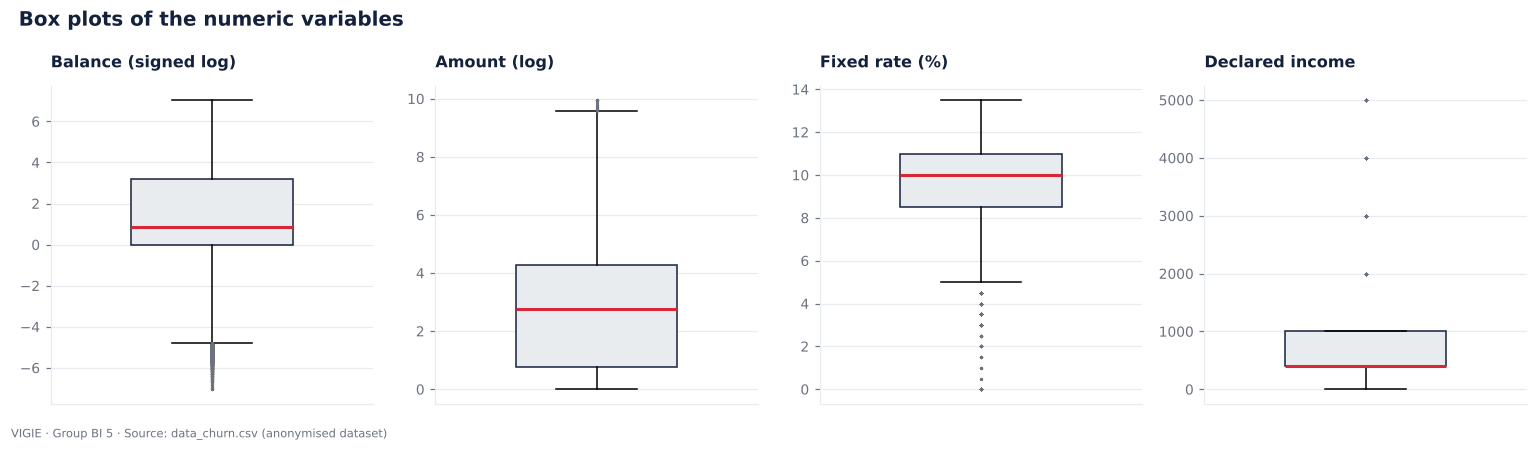

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (name, s, transform) in zip(axes, [
        ("Balance (signed log)", accounts["ACCT_BALANCE"], signed_log),
        ("Amount (log)", accounts["AMOUNT"], lambda x: np.log10(1 + x.clip(lower=0))),
        ("Fixed rate (%)", accounts["FIXEDRATE"], lambda x: x),
        ("Declared income", customers["SALARY"], lambda x: x)]):
    ax.boxplot(transform(s.dropna()), vert=True, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=C["mist"], color=C["ink"]),
               medianprops=dict(color=C["churn"], lw=2),
               flierprops=dict(marker=".", markersize=2, alpha=0.25, markerfacecolor=C["grey"], markeredgecolor=C["grey"]))
    ax.set_title(name, fontsize=10.5)
    ax.set_xticks([])
fig.suptitle("Box plots of the numeric variables", x=0.01, ha="left", fontweight="bold", color=C["ink"], fontsize=13)
fig.tight_layout()
style.save(fig, "01_outliers_boxplots")
plt.show()

In [26]:
# Who are the balance "outliers"? Breakdown by sign and by account family.
s = accounts[accounts["ACCT_BALANCE"].notna()].copy()
q1, q3 = s["ACCT_BALANCE"].quantile([.25, .75])
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
s["OUTLIER"] = (s["ACCT_BALANCE"] < low) | (s["ACCT_BALANCE"] > high)
s["SIGN"] = np.where(s["ACCT_BALANCE"] < 0, "Negative balance (in debit)", np.where(s["ACCT_BALANCE"] == 0, "Zero balance", "Positive balance"))
display(s.groupby("SIGN")["OUTLIER"].agg(Accounts="size", IQR_outliers="sum", Outlier_share="mean").round(3))
by_family = s.groupby("ACCOUNT_TYPE_DESC")["OUTLIER"].agg(Accounts="size", Outlier_share="mean")
by_family["Median balance"] = s.groupby("ACCOUNT_TYPE_DESC")["ACCT_BALANCE"].median()
display(by_family.sort_values("Outlier_share", ascending=False).round(3))

,Accounts,IQR_outliers,Outlier_share
SIGN,,,
Negative balance (in debit),60387,39899,0.661
Positive balance,186450,59463,0.319
Zero balance,62994,0,0.000


,Accounts,Outlier_share,Median balance
ACCOUNT_TYPE_DESC,,,
Credit immobilier,15953,0.944,-27000.0
Credit investissement,3403,0.916,-34000.0
Credit automobile,1187,0.881,-15000.0
Credit consommation,15495,0.558,-3200.0
Comptes courants,22224,0.440,290.0
Contentieux,14289,0.396,-1100.0
Placements a terme,5790,0.331,0.0
Epargne,176588,0.255,200.0
Financement court terme,22270,0.211,0.0


**Reading — outliers**

* **Balance**: 32% of balances fall outside the IQR bounds, as announced by the supervisors. This is **not** a
  third of errors. The breakdown shows it: the **loan** families (mortgage, investment, car) have a negative
  median balance and are ≈ 90% "out of bounds"; consumer credit is 56% out. The reason is mechanical: most
  accounts are small-balance savings accounts, which narrows the IQR interval to [−2,400 ; 4,000]. A negative
  balance is therefore **business information** (an account in debit), not an anomaly.
* **Amount**: 20% outliers, almost all on the high side (large outstanding amounts), including the pile-up on the cap.
* **Fixed rate**: 10.6% outliers, all on the low side (rates below 4.8%). Most rates lie between 8.5% and 11%;
  the low rates form a second, smaller group of values, which is kept.
* **Declared income**: 15.9% outliers, all on the high side. Half of the declared incomes equal 400, so any
  value ≥ 2,000 falls outside the bounds. This is an effect of rounding, not an anomaly.
* The **z-score** flags far fewer points than IQR on the amounts: the extreme values inflate the standard
  deviation and hide themselves. This is why IQR is our reference method.

**Decision.** No row is removed because it is an outlier. In the warehouse the value is kept and a direction flag
(`is_overdrawn`) is added; in the analyses we use the **median** and **bands** rather than the mean. These
balance and amount variables are excluded from the churn model anyway (target leakage).

## 7. Summary table per variable

Milestone 1 deliverable: for each variable — type, % missing, number of outliers, method, proposed decision.

In [27]:
types = {
    "CUSTOMER_NO": "Identifier", "ACCOUNT_NO": "Identifier", "BRANCH_GROUP": "Qualitative (21)",
    "NATIONALITY_REGION": "Qualitative (6)", "RESIDENCE_REGION": "Qualitative (6)", "MARITAL_STATUS": "Qualitative (4)",
    "BIRTH_PERIOD": "Discrete quantitative", "CUST_OPENING_DATE": "Date (variable precision)",
    "NATURE_CLIENT": "Qualitative (5)", "PARTYCLASS": "Qualitative (4)", "LOB": "Qualitative (6)",
    "SCORE_KYC": "Ordinal qualitative (5)", "COMPLETED_FILE": "Binary (YES / blank)",
    "LAST_REVIEW_DATE": "Date (month)", "NEXT__REVIEW_DATE": "Date (month)", "INDUSTRY": "Qualitative (21)",
    "SALARY": "Rounded quantitative", "ACCOUNT_STATUS": "Binary — target", "ACCT_OPENING_DATE": "Date (week)",
    "ACCT_CLOSE_DATE": "Date (week)", "ACCOUNT_CATEGORY": "Qualitative (14)", "ACCOUNT_TYPE_DESC": "Qualitative (14)",
    "CURRENCY": "Qualitative (5)", "CLOSURE_REASON": "Qualitative (12)", "ACCT_BALANCE": "Continuous quantitative",
    "PRODUCT_GROUP": "Qualitative (12)", "PRODUCT_LINE": "Qualitative (4)", "STARTDATE": "Date (month)",
    "MATURITYDATE": "Date (month)", "AMOUNT": "Continuous quantitative", "FIXEDRATE": "Discrete quantitative",
    "PRODUCT_STATUS": "Qualitative (7)",
}
blank_kind = {
    "ACCOUNT_NO": "Structural (customer with no account)", "ACCOUNT_STATUS": "Structural (customer with no account)",
    "ACCT_CLOSE_DATE": "Business (active account)", "CLOSURE_REASON": "Business (active account)",
    "ACCT_OPENING_DATE": "Tied to the closure ⚠", "ACCOUNT_CATEGORY": "Tied to the closure ⚠",
    "ACCOUNT_TYPE_DESC": "Tied to the closure ⚠", "CURRENCY": "Tied to the closure ⚠", "ACCT_BALANCE": "Tied to the closure ⚠",
    "PRODUCT_GROUP": "Tied to the closure ⚠", "PRODUCT_LINE": "Tied to the closure ⚠", "AMOUNT": "Tied to the closure ⚠",
    "STARTDATE": "Business (product without maturity)", "MATURITYDATE": "Business (product without maturity)",
    "FIXEDRATE": "Business (product without a rate)", "PRODUCT_STATUS": "Business (product without maturity)",
    "SALARY": "Declarative", "MARITAL_STATUS": "Declarative / anonymisation", "BIRTH_PERIOD": "Declarative / anonymisation",
    "COMPLETED_FILE": "Meaningful (incomplete file)", "CUST_OPENING_DATE": "Anonymisation",
    "LAST_REVIEW_DATE": "Structural (customer with no account)", "NEXT__REVIEW_DATE": "Structural (customer with no account)",
    "SCORE_KYC": "Residual",
}
decision = {
    "CUSTOMER_NO": "Key of the customer dimension; never displayed",
    "ACCOUNT_NO": "Key of the account fact; rows without an account → customer dimension only",
    "BRANCH_GROUP": "Branch dimension; AG00 = \"masked\"",
    "NATIONALITY_REGION": "Keep; redundant with residence",
    "RESIDENCE_REGION": "Keep; group the rare categories",
    "MARITAL_STATUS": "Blank → \"Not provided\" category",
    "BIRTH_PERIOD": "Derive age and age band",
    "CUST_OPENING_DATE": "Convert; derive customer tenure",
    "NATURE_CLIENT": "Keep; TRPP/TRPM → \"Other\"",
    "PARTYCLASS": "Keep (commercial segment)",
    "LOB": "Join TARGET.xlsx; redundant with PARTYCLASS",
    "SCORE_KYC": "Keep; blank → \"Not provided\"",
    "COMPLETED_FILE": "Recode as 0/1 (blank = incomplete)",
    "LAST_REVIEW_DATE": "Convert; derive months since review",
    "NEXT__REVIEW_DATE": "Convert; derive months to next review",
    "INDUSTRY": "Join INDUSTRY.xlsx; Z = not provided",
    "SALARY": "Keep the blank (not declared); treat in bands",
    "ACCOUNT_STATUS": "Target: Closed = 1, Active = 0",
    "ACCT_OPENING_DATE": "Convert; flag if later than the closing; excluded from the model (leakage)",
    "ACCT_CLOSE_DATE": "Keep the 1st date; time series; excluded from the model (leakage)",
    "ACCOUNT_CATEGORY": "Join the reference file; excluded from the model (leakage)",
    "ACCOUNT_TYPE_DESC": "Redundant with ACCOUNT_CATEGORY",
    "CURRENCY": "Join the reference file; excluded from the model (leakage)",
    "CLOSURE_REASON": "Join the reference file; excluded from the model (leakage)",
    "ACCT_BALANCE": "Keep negatives (in debit); median and bands; excluded from the model (leakage)",
    "PRODUCT_GROUP": "Product dimension; excluded from the model (leakage)",
    "PRODUCT_LINE": "Product dimension; excluded from the model (leakage)",
    "STARTDATE": "Convert; descriptive use",
    "MATURITYDATE": "Convert; descriptive use",
    "AMOUNT": "Keep; pile-up at the cap = artefact; excluded from the model (leakage)",
    "FIXEDRATE": "Keep; descriptive use",
    "PRODUCT_STATUS": "Descriptive use; excluded from the model (leakage)",
}
summary_table = pd.DataFrame({
    "Type": pd.Series(types),
    "% missing (rows)": missing["% missing (rows)"],
    "% missing (natural grain)": missing["% missing (natural grain)"],
    "Kind of blank": pd.Series(blank_kind),
})
summary_table["IQR outliers"] = outlier_table["IQR outliers"].reindex(summary_table.index)
summary_table["z-score outliers"] = outlier_table["z-score outliers"].reindex(summary_table.index)
summary_table["Proposed decision"] = pd.Series(decision)
summary_table = summary_table.loc[list(raw.columns)]
summary_table["Kind of blank"] = summary_table["Kind of blank"].fillna("—")
shown = summary_table.copy()
for c in ["IQR outliers", "z-score outliers"]:
    shown[c] = shown[c].map(lambda v: "—" if pd.isna(v) else n(v))
display(shown)

,Type,% missing (rows),% missing (natural grain),Kind of blank,IQR outliers,z-score outliers,Proposed decision
CUSTOMER_NO,Identifier,0.0,0.0,—,—,—,Key of the customer dimension; never displayed
ACCOUNT_NO,Identifier,9.1,0.0,Structural (customer with no account),—,—,Key of the account fact; rows without an accou...
NATIONALITY_REGION,Qualitative (6),0.0,0.0,—,—,—,Keep; redundant with residence
RESIDENCE_REGION,Qualitative (6),0.0,0.0,—,—,—,Keep; group the rare categories
MARITAL_STATUS,Qualitative (4),16.5,10.9,Declarative / anonymisation,—,—,"Blank → ""Not provided"" category"
CUST_OPENING_DATE,Date (variable precision),3.5,4.3,Anonymisation,—,—,Convert; derive customer tenure
BIRTH_PERIOD,Discrete quantitative,13.2,6.4,Declarative / anonymisation,0,0,Derive age and age band
NATURE_CLIENT,Qualitative (5),0.0,0.0,—,—,—,"Keep; TRPP/TRPM → ""Other"""
BRANCH_GROUP,Qualitative (21),0.0,0.0,—,—,—,"Branch dimension; AG00 = ""masked"""
SCORE_KYC,Ordinal qualitative (5),0.2,0.2,Residual,—,—,"Keep; blank → ""Not provided"""


In [28]:
# Export of the summary table (milestone 1 deliverable) — aggregates only.
md = [
    "# Summary per variable — milestone 1",
    "",
    f"> Generated by `01_etl/notebooks/01_univariate_analysis.ipynb` · {config.PROJECT_NAME} · {config.GROUP}  ",
    f"> File analysed: `data_churn.csv` — SHA-256 `{fingerprint['sha256'][:16]}…` — {n(len(raw))} rows, {raw.shape[1]} columns.",
    "",
    "Outlier method: **IQR** (outside `[Q1 − 1.5·IQR ; Q3 + 1.5·IQR]`, reference method) and **z-score** (`|z| > 3`), "
    "computed at the natural grain of the variable (account or customer). No row is removed because it is an outlier.",
    "",
    "| Variable | Type | % missing (rows) | % missing (natural grain) | Kind of blank | IQR outliers | z-score outliers | Proposed decision |",
    "|---|---|---:|---:|---|---:|---:|---|",
]
for var, r in shown.iterrows():
    md.append(
        f"| `{var}` | {r['Type']} | {r['% missing (rows)']:.1f} | {r['% missing (natural grain)']:.1f} | "
        f"{r['Kind of blank']} | {r['IQR outliers']} | {r['z-score outliers']} | {r['Proposed decision']} |")
md += [
    "",
    "**Derived variables checked** (customer grain):",
    "",
    "| Derived variable | IQR outliers | % | z-score outliers | Comment |",
    "|---|---:|---:|---:|---|",
]
comments = {
    "N_ACCOUNTS (derived)": "Distribution concentrated on 1: any multi-account customer falls outside the bounds. Useful information, kept.",
    "CUSTOMER_TENURE (derived)": "No outlying value.",
    "MONTHS_SINCE_REVIEW (derived)": "Very old reviews: files not reviewed, useful information.",
}
for name, comment in comments.items():
    r = outlier_table.loc[name]
    md.append(f"| {name} | {n(r['IQR outliers'])} | {r['% IQR']:.1f} | {n(r['z-score outliers'])} | {comment} |")
(ROOT / "01_etl" / "variable_summary.md").write_text("\n".join(md) + "\n", encoding="utf-8")
print("Table exported: 01_etl/variable_summary.md")

Table exported: 01_etl/variable_summary.md


## Conclusion of phase 1

1. **Integrity verified**: volumes match the supervisors' document, no invalid date, no orphan key.
2. **Grain clarified**: the file mixes three grains. We keep the **account** for the warehouse and the KPIs,
   and the **customer** for segmentation and prediction.
3. **Churn defined**: closed account. Rate of ≈ 40% per row, ≈ 36% per account, ≈ 32% per customer — and **no
   mixed customer**, which makes the customer-grain definition unambiguous.
4. **Missing values typed**: structural, business, declarative… and above all **tied to the closure**, which
   is a target leak to neutralise.
5. **Outliers interpreted, not removed**: negative balances are accounts in debit, extreme values come from capping.
6. **A date anomaly detected**: accounts closed "before" they were opened — flagged, not corrected.

➡ Next: bivariate analysis (bonus) in `02_bivariate_analysis.ipynb`, then the warehouse design (phase 2).